In [1]:
import pandas as pd
import numpy as np
import yfinance as yf

In [2]:
stk_data = yf.download("TATACONSUM.NS", start = "2022-06-01", end = "2023-01-05")

[*********************100%***********************]  1 of 1 completed


In [3]:
# Check whether the column names have multiple levels. Ex:("Close", "TATACONSUM.NS")
if stk_data.columns.nlevels > 1:
    stk_data.columns = stk_data.columns.get_level_values(0)  # Keep only the first level: Close, High, Low, Open, Volume.

In [4]:
stk_data = stk_data[["Open","High","Low","Close"]]

In [5]:
stk_data

Price,Open,High,Low,Close
Date,,,,
2022-06-01,729.168159,748.836511,727.009438,730.223511
2022-06-02,726.289846,729.647857,716.695528,727.489136
2022-06-03,729.168123,739.721872,721.540629,723.315613
2022-06-06,726.049942,738.762412,715.064437,732.670044
2022-06-07,731.086899,731.086899,715.831913,725.905945
...,...,...,...,...
2022-12-29,753.342962,753.342962,737.966618,750.538452
2022-12-30,752.375928,756.534292,739.804093,741.689880
2023-01-02,744.542716,745.606463,733.131312,737.192993


In [6]:
column = "Close"

In [7]:
from sklearn.preprocessing import MinMaxScaler
Ms = MinMaxScaler()
data1 = Ms.fit_transform(stk_data[[column]])
print("Len:", data1.shape)

Len: (150, 1)


In [8]:
len(data1)

150

In [9]:
training_size = round(len(data1 ) * 0.80)
print(training_size)

X_train = data1[:training_size]
X_test = data1[training_size:]
print("X_train length:", X_train.shape)
print("X_test length:", X_test.shape)

y_train = data1[:training_size]
y_test = data1[training_size:]
print("y_train length:", y_train.shape)
print("y_test length:", y_test.shape)

120
X_train length: (120, 1)
X_test length: (30, 1)
y_train length: (120, 1)
y_test length: (30, 1)


In [17]:
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

for lag in [5,10,15,20,30]:

    model = AutoReg(X_train, lags=lag)
    model_fit = model.fit()

    y_pred = model_fit.predict(
        start=len(X_train),
        end=len(data1)-1
    )

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"Lag={lag}")
    print("RMSE =", rmse)
    print("R2 =", r2)
    print("----------------")

Lag=5
RMSE = 0.18141086777536292
R2 = -1.5470779973639428
----------------
Lag=10
RMSE = 0.17064995687124604
R2 = -1.2538655652839754
----------------
Lag=15
RMSE = 0.1542339386742239
R2 = -0.8410922138878894
----------------
Lag=20
RMSE = 0.15324431287432086
R2 = -0.8175416638651261
----------------
Lag=30
RMSE = 0.13690926103348916
R2 = -0.45071230727231537
----------------


In [18]:
# AR Model
from statsmodels.tsa.ar_model import AutoReg

model = AutoReg(X_train, lags=10)
model_fit = model.fit()

y_pred = model_fit.predict(
    start=len(X_train),
    end=len(data1)-1
)

In [19]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R2:", r2)

RMSE: 0.17064995687124604
R2: -1.2538655652839754


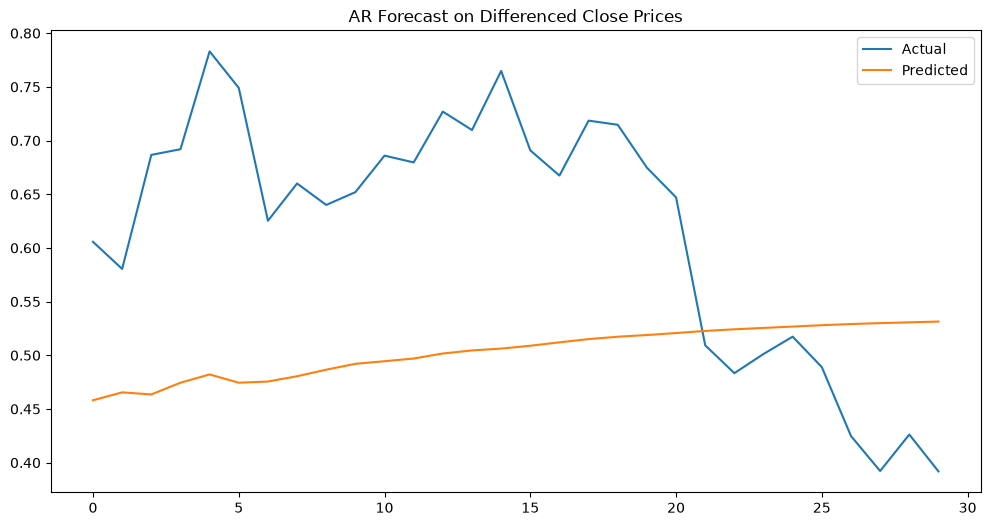

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(y_test, label="Actual")
plt.plot(y_pred, label="Predicted")
plt.legend()
plt.title("AR Forecast on Differenced Close Prices")
plt.show()